# Adaptive Pole-Stability Reward Shaping (DQN)

**Assignment 3 strategy:** modify the training reward so that the agent receives a larger reward when the pole is close to upright. Keep the assignment's provided DQN neural-network architecture unchanged.

## Research question

Does a smooth Gaussian reward based on pole angle improve DQN performance across pole lengths from 0.4 to 1.8, including the disturbance and increasing-force phases used by the supplied evaluation script?

## Hypothesis

H1: A dense, angle-sensitive reward will encourage the agent to keep the pole closer to upright. and will improve robustness across pole lengths and disturbances.   
H01: A dense, angle-sensitive reward will not encourage the agent to keep the pole closer to upright.

H2: A dense, angle-sensitive reward will significantly improve robustness across pole lengths and disturbances. 
H02: A dense, angle-sensitive reward will not significantly improve robustness across pole lengths and disturbances. 

## Important reward-design detail

The Gaussian reward below is always between 0 and 1. So we need to change the code a bit for the negative values near the threshold.

## 1. Imports and reproducibility

In [1]:
import random
from collections import deque
from dataclasses import dataclass
from pathlib import Path
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import gymnasium as gym
import time 
import matplotlib.pyplot as plt
import random
from network import *

VALIDATION_LENGTHS = [0.43, 0.69, 0.93, 1.17, 1.41, 1.69, 1.77]
VALIDATION_EPISODES_PER_LENGTH = 5
VALIDATE_EVERY = 100
STABILITY_THRESHOLD = 40
STABILITY_BONUS = 1.0

WEIGHTS_DIR = Path("weights")
WEIGHTS_DIR.mkdir(exist_ok=True)


## 2. Define the Gaussian stability reward

\[
reward = np.exp(-(pole_angle ** 2) / (2 * sigma ** 2))
\]

- \(\theta\) is the pole angle in radians (`observation[2]` in CartPole-v1).
- \(\sigma\) controls how sharply the reward falls as the pole tilts.
- A smaller \(\sigma\) gives high reward only when the pole is very close to upright.
- The default `SIGMA = 0.1` is an experimental choice, not a literature-established optimum.


In [2]:
def gaussian_stability_reward(pole_angle, sigma=SIGMA):
    """Return a smooth reward in [0, 1], maximized at pole_angle == 0."""
    if sigma <= 0:
        raise ValueError("sigma must be positive")
    return float(np.exp(-(float(pole_angle) ** 2) / (2.0 * sigma ** 2)))

def shaped_reward(observation, terminated, steps,sigma=SIGMA,
                terminal_penalty=TERMINAL_PENALTY,stability_threshold=STABILITY_THRESHOLD,
                stability_bonus=STABILITY_BONUS,):
    """Reward for one transition. `observation` is the next observation."""

    angle = float(observation[2])
    reward = gaussian_stability_reward(angle, sigma=sigma)
    if terminated:
        reward -= terminal_penalty
    if steps == stability_threshold and not terminated:
        reward += stability_bonus

    return reward

## 3. Inspect the reward curve and validation

This plot helps explain the role of sigma in the report. Angles are shown in radians.

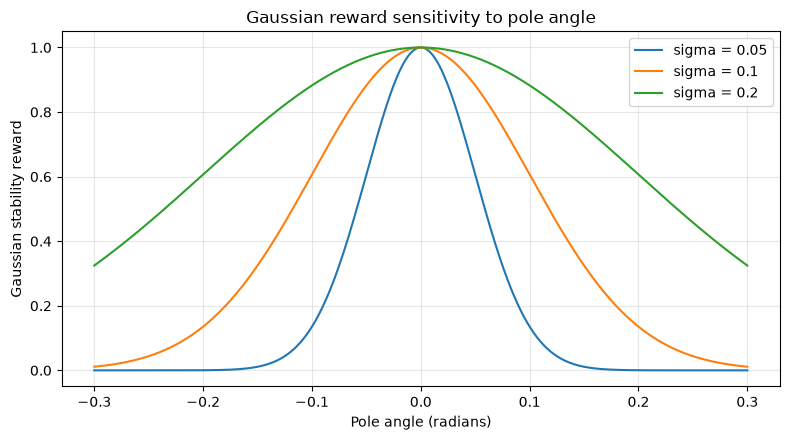

In [3]:
angles = np.linspace(-0.3, 0.3, 601)
plt.figure(figsize=(8, 4.5))
for sigma in (0.05, 0.1, 0.2):
    rewards = [gaussian_stability_reward(a, sigma) for a in angles]
    plt.plot(angles, rewards, label=f"sigma = {sigma}")
plt.xlabel("Pole angle (radians)")
plt.ylabel("Gaussian stability reward")
plt.title("Gaussian reward sensitivity to pole angle")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

def evaluate_policy(policy_net, lengths=VALIDATION_LENGTHS,
                    episodes_per_length=VALIDATION_EPISODES_PER_LENGTH):
    env = gym.make("CartPole-v1")
    policy_net.eval()
    per_length = {}

    for length in lengths:
        scores = []
        for episode_idx in range(episodes_per_length):
            env.unwrapped.length = float(length)
            state, info = env.reset(seed=SEED + episode_idx)
            steps = 0
            for _ in range(MAX_STEPS):
                state_tensor = torch.tensor(
                    state, dtype=torch.float32, device=device
                ).unsqueeze(0)
                with torch.no_grad():
                    action = policy_net(state_tensor).argmax(dim=1).item()
                state, _, terminated, truncated, info = env.step(action)
                steps += 1
                if terminated or truncated:
                    break
            scores.append(steps)

        per_length[float(length)] = {
            "mean_steps": float(np.mean(scores)),
            "std_steps": float(np.std(scores)),
            "scores": scores,
        }

    env.close()
    policy_net.train()
    all_scores = [score for item in per_length.values() for score in item["scores"]]
    return float(np.mean(all_scores)), per_length


## 4. Training-loop integration

Using the **next observation's pole angle** to compute the reward stored in replay memory. 

The integration follows this order:

1. `next_obs, env_reward, terminated, truncated, info = env.step(action)`
2. Compute `train_reward = shaped_reward(next_obs, terminated)`
3. Store `(obs, action, train_reward, next_obs, done)` in replay memory.
4. Train DQN as usual.
5. Advance `obs = next_obs`.


In [4]:
# --- Integration pattern: adapt variable names to your provided DQN code ---
#
# next_obs, env_reward, terminated, truncated, info = env.step(action)
#
# train_reward = shaped_reward(
#     observation=next_obs,
#     terminated=terminated,
#     sigma=SIGMA,
#     terminal_penalty=TERMINAL_PENALTY,
# )
#
# done = terminated or truncated
# replay_buffer.push(obs, action, train_reward, next_obs, done)
# obs = next_obs

# one time visualization of the shaped reward function in action
"""env = gym.make("CartPole-v1", render_mode="human")

observation, info = env.reset()
delay = 0.2  #adjust if you want faster / slower visualization
steps = 0
total_shaped_reward = 0

while 1 > 0:

    action = env.action_space.sample()
    observation, reward, terminated, truncated, info = env.step(action)

    reward = shaped_reward(
        observation=observation,
        terminated=terminated,
        sigma=SIGMA,
        terminal_penalty=TERMINAL_PENALTY,
    )
    total_shaped_reward += reward
    steps += 1
    time.sleep(delay) 
    
    if terminated or truncated:
        print(f"Episode ended after {steps} steps.")
        print(f"Total shaped reward: {total_shaped_reward:.2f}")
        break

    time.sleep(delay)
env.close()"""


'env = gym.make("CartPole-v1", render_mode="human")\n\nobservation, info = env.reset()\ndelay = 0.2  #adjust if you want faster / slower visualization\nsteps = 0\ntotal_shaped_reward = 0\n\nwhile 1 > 0:\n\n    action = env.action_space.sample()\n    observation, reward, terminated, truncated, info = env.step(action)\n\n    reward = shaped_reward(\n        observation=observation,\n        terminated=terminated,\n        sigma=SIGMA,\n        terminal_penalty=TERMINAL_PENALTY,\n    )\n    total_shaped_reward += reward\n    steps += 1\n    time.sleep(delay) \n\n    if terminated or truncated:\n        print(f"Episode ended after {steps} steps.")\n        print(f"Total shaped reward: {total_shaped_reward:.2f}")\n        break\n\n    time.sleep(delay)\nenv.close()'

## 5. Training over multiple pole lengths

This helper sets only the pole length. Use `env.unwrapped.length`.

In [5]:
def train_agent():
    env = gym.make("CartPole-v1")
    state_dim = env.observation_space.shape[0]
    action_dim = env.action_space.n

    policy_net = QNetwork(state_dim, action_dim).to(device)
    target_net = QNetwork(state_dim, action_dim).to(device)
    target_net.load_state_dict(policy_net.state_dict())
    target_net.eval()

    optimizer = optim.Adam(policy_net.parameters(), lr=LEARNING_RATE)
    replay_buffer = ReplayBuffer(BUFFER_SIZE)

    shaped_returns, episode_steps_history, losses = [], [], []
    training_rows, validation_rows, validation_detail_rows = [], [], []
    total_steps = 0
    best_validation_score = -np.inf
    best_path = WEIGHTS_DIR / "gaussian_pole_stability.pth"

    for episode in range(NUM_EPISODES):
        length = float(np.random.uniform(MIN_POLE_LENGTH, MAX_POLE_LENGTH))
        env.unwrapped.length = length
        state, info = env.reset(seed=SEED + episode)
        episode_return, steps = 0.0, 0
        epsilon = get_epsilon(total_steps)

        for _ in range(MAX_STEPS):
            epsilon = get_epsilon(total_steps)
            action = select_action(state, policy_net, epsilon)
            next_state, _, terminated, truncated, info = env.step(action)
            done = terminated or truncated

            reward = shaped_reward(
                observation=next_state,
                terminated=terminated,
                steps = steps + 1,
                sigma=SIGMA,
                terminal_penalty=TERMINAL_PENALTY,
            )
            replay_buffer.push(state, action, reward, next_state, terminated)
            loss = update_dqn(policy_net, target_net, optimizer, replay_buffer)
            if loss is not None:
                losses.append(loss)

            state = next_state
            episode_return += reward
            steps += 1
            total_steps += 1

            if total_steps % TARGET_UPDATE_FREQ == 0:
                target_net.load_state_dict(policy_net.state_dict())
            if done:
                break

        shaped_returns.append(episode_return)
        episode_steps_history.append(steps)
        training_rows.append({
            "episode": episode + 1,
            "pole_length": length,
            "shaped_return": episode_return,
            "episode_steps": steps,
            "epsilon": epsilon,
        })

        if (episode + 1) % 100 == 0:
            print(
                f"Episode {episode + 1}/{NUM_EPISODES} | "
                f"mean shaped return (last 100): {np.mean(shaped_returns[-100:]):.2f} | "
                f"mean steps (last 100): {np.mean(episode_steps_history[-100:]):.1f} | "
                f"epsilon: {epsilon:.3f}"
            )

        if (episode + 1) % VALIDATE_EVERY == 0:
            val_mean, by_length = evaluate_policy(policy_net)
            validation_rows.append({
                "episode": episode + 1,
                "mean_validation_steps": val_mean,
            })
            for val_length, result in by_length.items():
                validation_detail_rows.append({
                    "episode": episode + 1,
                    "pole_length": val_length,
                    "mean_steps": result["mean_steps"],
                    "std_steps": result["std_steps"],
                })

            print(f"  Validation mean episode length: {val_mean:.1f} steps")
            if val_mean > best_validation_score:
                best_validation_score = val_mean
                torch.save(policy_net.state_dict(), best_path)
                print(f"  Saved best checkpoint: {best_path}")

    env.close()
    torch.save(policy_net.state_dict(), WEIGHTS_DIR / "gaussian_pole_stability_last.pth")
    pd.DataFrame(training_rows).to_csv('results/training_history_reward_shaping.csv', index=False)
    pd.DataFrame(validation_rows).to_csv('results/validation_history_reward_shaping.csv', index=False)
    pd.DataFrame(validation_detail_rows).to_csv('results/validation_by_length_reward_shaping.csv', index=False)

    print("\nTraining finished.")
    print("Best validation mean:", best_validation_score)
    print("Best model:", best_path)
    print("Saved training_history.csv, validation_history.csv, validation_by_length.csv")
    return shaped_returns, episode_steps_history, losses, validation_rows, validation_detail_rows


shaped_returns, episode_steps, losses, validation_history, validation_by_length = train_agent()


Episode 100/3000 | mean shaped return (last 100): 22.51 | mean steps (last 100): 32.4 | epsilon: 0.939
  Validation mean episode length: 372.8 steps
  Saved best checkpoint: weights/gaussian_pole_stability.pth
Episode 200/3000 | mean shaped return (last 100): 29.83 | mean steps (last 100): 42.0 | epsilon: 0.859
  Validation mean episode length: 499.7 steps
  Saved best checkpoint: weights/gaussian_pole_stability.pth
Episode 300/3000 | mean shaped return (last 100): 53.49 | mean steps (last 100): 68.9 | epsilon: 0.728
  Validation mean episode length: 478.3 steps
Episode 400/3000 | mean shaped return (last 100): 102.18 | mean steps (last 100): 123.3 | epsilon: 0.493
  Validation mean episode length: 452.2 steps
Episode 500/3000 | mean shaped return (last 100): 322.80 | mean steps (last 100): 338.7 | epsilon: 0.050
  Validation mean episode length: 295.0 steps
Episode 600/3000 | mean shaped return (last 100): 415.57 | mean steps (last 100): 432.9 | epsilon: 0.050
  Validation mean episod

## 6. Training and validation plots


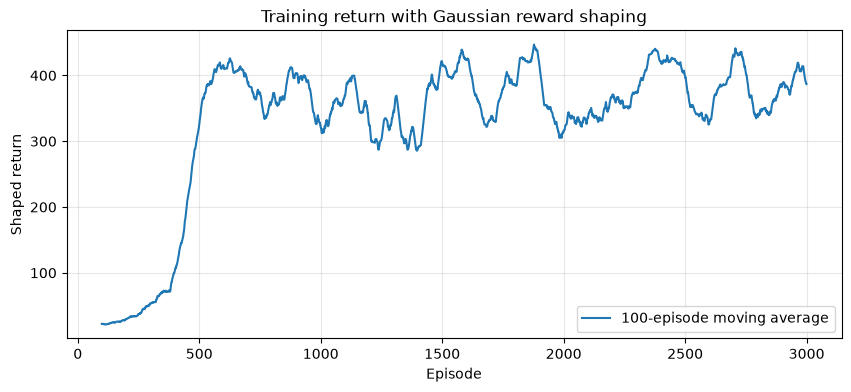

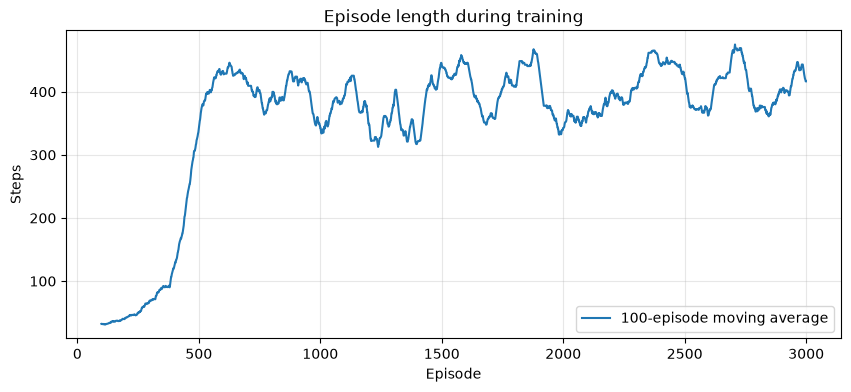

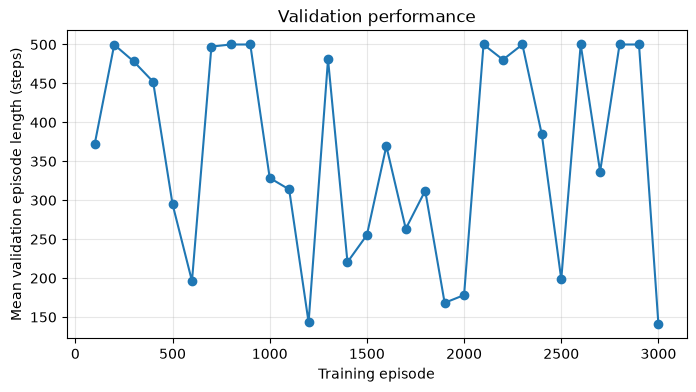

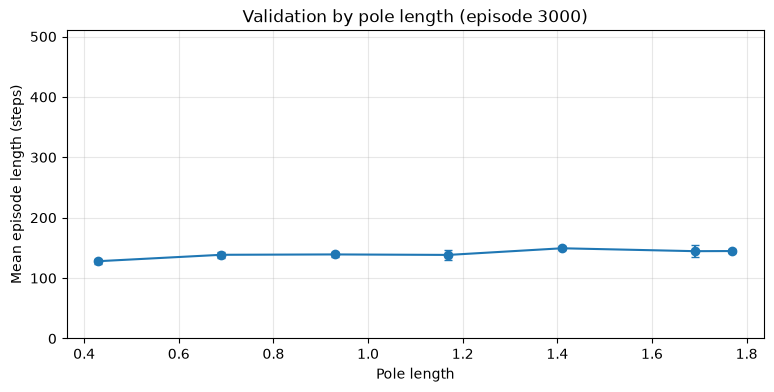

,episode,pole_length,mean_steps,std_steps
0,3000,0.43,128.0,4.242641
1,3000,0.69,138.6,4.630335
2,3000,0.93,139.2,4.833218
3,3000,1.17,138.4,8.662563
4,3000,1.41,149.4,3.611094
5,3000,1.69,144.6,9.436101
6,3000,1.77,144.8,3.655133


In [7]:
def plot_moving_average(values, label, ylabel, title, window=100):
    values = np.asarray(values, dtype=float)
    plt.figure(figsize=(10, 4))
    if len(values) >= window:
        avg = np.convolve(values, np.ones(window) / window, mode="valid")
        plt.plot(np.arange(window - 1, len(values)), avg, label=f"{window}-episode moving average")
    else:
        plt.plot(values, label=label)
    plt.xlabel("Episode")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()

plot_moving_average(shaped_returns, "Shaped return", "Shaped return",
                    "Training return with Gaussian reward shaping")
plot_moving_average(episode_steps, "Episode steps", "Steps",
                    "Episode length during training")

if validation_history:
    val_df = pd.DataFrame(validation_history)
    plt.figure(figsize=(8, 4))
    plt.plot(val_df["episode"], val_df["mean_validation_steps"], marker="o")
    plt.xlabel("Training episode")
    plt.ylabel("Mean validation episode length (steps)")
    plt.title("Validation performance")
    plt.grid(alpha=0.3)
    plt.show()

if validation_by_length:
    detail_df = pd.DataFrame(validation_by_length)
    latest_episode = detail_df["episode"].max()
    latest = detail_df[detail_df["episode"] == latest_episode].sort_values("pole_length")
    plt.figure(figsize=(9, 4))
    plt.errorbar(latest["pole_length"], latest["mean_steps"],
                 yerr=latest["std_steps"], marker="o", capsize=3)
    plt.xlabel("Pole length")
    plt.ylabel("Mean episode length (steps)")
    plt.title(f"Validation by pole length (episode {latest_episode})")
    plt.ylim(0, MAX_STEPS + 10)
    plt.grid(alpha=0.3)
    plt.show()
    display(latest.reset_index(drop=True))


## 7. Evaluation and reporting checklist

Parameters to record:
- Mean and standard deviation of score for each of the 30 pole lengths.
- Overall average across all 30 lengths.
- The same metrics for the group's baseline DQN, trained with the standard CartPole reward.
- The exact training-length schedule, number of episodes, seed(s), sigma, terminal penalty, and all unchanged DQN hyperparameters.
- A statistical comparison across repeated runs if required by your group's analysis plan.
- The best validation checkpoint is `weights/gaussian_pole_stability.pth`.
- Run the separate `adaptive_pole_stability_final_test.ipynb` from this project directory, or ensure the `weights/` directory is available there.
- The final test accumulates the environment's standard reward and applies the supplied force schedule. It does not use the Gaussian reward, so report the two metrics separately.
- Use validation for checkpoint selection and the final test for the final reported result.


*Use the **provided evaluation script's score/episode performance** for the main comparison.

## 8. References

1. Ng, A. Y., Harada, D., & Russell, S. (1999). *Policy Invariance Under Reward Transformations: Theory and Application to Reward Shaping*. Proceedings of ICML.
   https://ai.stanford.edu/~ang/papers/shaping-icml99.pdf

2. Suay, H. B., et al. (2015). *Reward Shaping by Demonstration*. Verify the publication metadata and the specific claims you attribute to this work before submission.
   https://publications.ri.cmu.edu/reward-shaping-by-demonstration
